# 01 — Exploratory Data Analysis

**Goal:** understand the dataset before modeling. These cells use the supplied CSV only; no real findings are claimed until you run them.

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Read data/README.md and place the permitted CSV there."
    )
df = pd.read_csv(DATA_PATH)
if "Attrition" not in df.columns:
    raise ValueError("Expected target column 'Attrition'. Check data/README.md.")
print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Data quality and structure

In [9]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_values"))
display(df.describe(include="all").T.head(30))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

None

,missing_values
Age,0
StandardHours,0
NumCompaniesWorked,0
Over18,0
OverTime,0
PercentSalaryHike,0
PerformanceRating,0
RelationshipSatisfaction,0
StockOptionLevel,0
MonthlyIncome,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


## Attrition distribution

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Percentages:


,percent
Attrition,
No,83.88
Yes,16.12


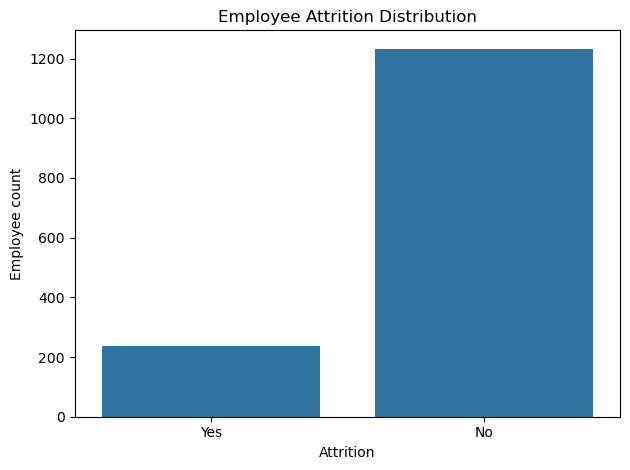

In [11]:
print(df["Attrition"].value_counts(dropna=False))
print("\nPercentages:")
display((df["Attrition"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

ax = sns.countplot(data=df, x="Attrition")
ax.set_title("Employee Attrition Distribution")
ax.set_xlabel("Attrition")
ax.set_ylabel("Employee count")
plt.tight_layout()
plt.savefig("../reports/attrition_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## Numeric feature comparisons

The following plot is exploratory and does not establish causation.

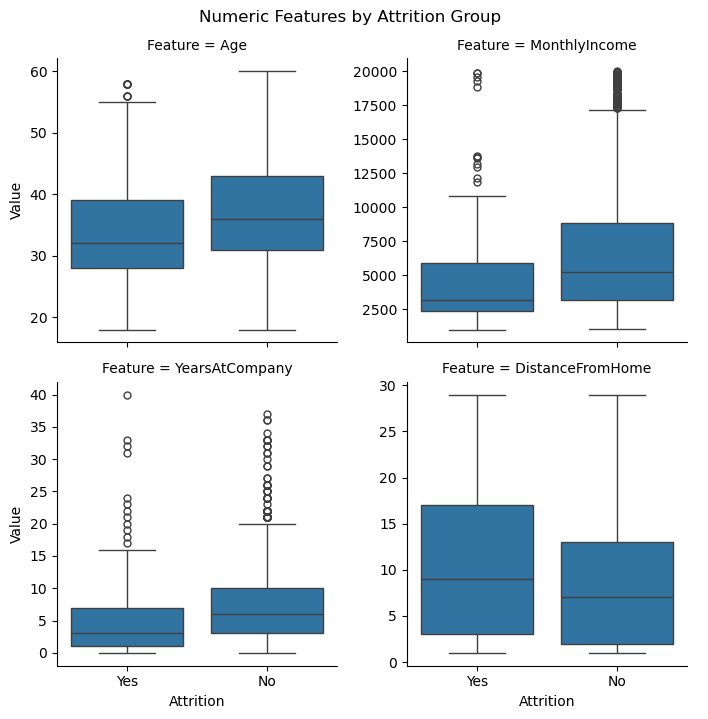

In [13]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    selected = [c for c in ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"] if c in numeric_cols]
    if selected:
        long_df = df.melt(id_vars="Attrition", value_vars=selected, var_name="Feature", value_name="Value")
        g = sns.catplot(data=long_df, x="Attrition", y="Value", col="Feature",
                        kind="box", col_wrap=2, sharey=False, height=3.5)
        g.fig.suptitle("Numeric Features by Attrition Group", y=1.02)
        plt.savefig("../reports/numeric_features_by_attrition.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("No expected numeric comparison columns found; inspect df.columns and choose features.")


## Record observations

### Record of Observation – Week 1: Exploratory Data Analysis

1. The dataset contains 1,470 employee records and 35 columns.
2. The target variable, **Attrition**, contains two categories: Yes and No.
3. A total of 237 employees (16.12%) are labelled as having left the company, while 1,233 employees (83.88%) are labelled as not having left.
4. The dataset contains both numerical and categorical variables.
5. The attrition distribution indicates that the dataset is imbalanced, as the number of employees in the No category is much higher than in the Yes category.
6. Data inspection and visualizations were performed to understand the distribution of employee attributes and identify patterns that may be useful for prediction.
7. The observations from this analysis will help guide data preprocessing, feature selection, and machine-learning model development in the next stages.

**Conclusion:** The initial exploratory data analysis provided an understanding of the dataset structure and attrition distribution. Further preprocessing and model evaluation are required to identify useful predictors of employee attrition.